<a href="https://colab.research.google.com/github/Abdoulaye279/Abdoulaye_koita/blob/main/Porte_CNOT_de_Cirac%E2%80%93Zoller.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Porte CNOT de Cirac–Zoller : simulation, bruit corrélé, états excités du bus, Mølmer–Sørensen et Qiskit
Projet basé sur Schmidt-Kaler et al., *Nature* 422, 408 (2003).

**Parties**
1. Modèle et porte idéale (table de vérité, état de Bell, parité)
2. Budget d'erreur et comparaison avec l'expérience
3. **Bruit de phase corrélé dans le temps**
4. **États excités du bus** (température du mode de vibration)
5. **Comparaison avec la porte de Mølmer–Sørensen**
6. **Export vers Qiskit** et comparaison avec un simulateur de circuit



## 1. Modèle physique
- Qubit : |S⟩ = |0⟩ (S₁/₂), |D⟩ = |1⟩ (D₅/₂). Le bus est un oscillateur harmonique tronqué à 4 niveaux de phonons.
- Impulsion sur la **porteuse** R(θ, φ) : rotation du qubit seul.
- Impulsion sur la **bande latérale bleue** R⁺(θ, φ) : H ∝ e^{iφ} σ₊ a† + h.c., qui couple l'état électronique au phonon.
- Séquence (Tableau 1) : mapping ion 1 → bus ; Ramsey π/2 ; porte de phase composite (4 impulsions bleues sur l'ion 2) ; Ramsey π/2 ; mapping inverse.

In [ ]:
import numpy as np
from scipy.linalg import expm

N = 8
I2, IN = np.eye(2), np.eye(N)
sp = np.array([[0, 0], [1, 0]], complex)
sm = sp.conj().T
sx = sp + sm
sy = -1j * sp + 1j * sm
a = np.diag(np.sqrt(np.arange(1, N)), 1).astype(complex)
ad = a.conj().T
def k3(A, B, C): return np.kron(np.kron(A, B), C)
r2 = np.sqrt(2)

def carrier_G(j, ph, eps=0.0):
    s = np.cos(ph) * sx + np.sin(ph) * sy
    t, o = (k3(s, I2, IN), k3(I2, s, IN)) if j == 1 else (k3(I2, s, IN), k3(s, I2, IN))
    return t + eps * o

def blue_G(j, ph, eps=0.0):
    f = lambda A, B: np.exp(1j*ph) * k3(A, B, ad)
    t, o = (f(sp, I2), f(I2, sp)) if j == 1 else (f(I2, sp), f(sp, I2))
    G = t + eps * o
    return G + G.conj().T

# Tableau 1 : (type, ion, angle, phase)
SEQ = [("b",1,np.pi,0), ("c",2,np.pi/2,0), ("b",2,np.pi,0), ("b",2,np.pi/r2,np.pi/2),
       ("b",2,np.pi,0), ("b",2,np.pi/r2,np.pi/2), ("c",2,np.pi/2,np.pi), ("b",1,np.pi,np.pi)]

def pulse(kind, j, th, ph, eps=0.0, amp=1.0, dph=0.0):
    G = (carrier_G if kind == "c" else blue_G)(j, ph + dph, eps)
    H = amp * th / 2 * G

    return expm(-1j * H)

def gate(eps=0.0, amp_sig=0.0, ph_sig=0.0, rng=None):
    """Un tirage de la porte, avec erreurs aléatoires sur chaque impulsion."""
    U = np.eye(4 * N, dtype=complex)
    for kind, j, th, ph in SEQ:
        amp = 1 + (rng.normal(0, amp_sig) if amp_sig else 0)
        dph = rng.normal(0, ph_sig) if ph_sig else 0
        U = pulse(kind, j, th, ph, eps, amp, dph) @ U
    return U

def vec(i1, i2, n=0):
    v = np.zeros(4 * N, complex); v[(i1*2+i2)*N+n] = 1; return v

def run(psi_in_fn, shots=200, nth=0.0, **err):
    """Matrice densité 4x4 des ions (bus tracé) après la porte, moyennée sur 'shots'."""
    rng = np.random.default_rng(1)
    rho = np.zeros((4, 4), complex)
    for _ in range(shots):
        n0 = 1 if rng.random() < nth else 0
        U = gate(rng=rng, **err)
        out = U @ psi_in_fn(n0)
        M = out.reshape(4, N)
        rho += M @ M.conj().T
    return rho / shots

def truth_table(**kw):
    T = np.zeros((4, 4))
    for i, (x, y) in enumerate([(0,0),(0,1),(1,0),(1,1)]):
        rho = run(lambda n0: vec(x, y, n0), **kw)
        T[i] = np.real(np.diag(rho))
    return T

def bell_input(n0):
    return (vec(0, 0, n0) + vec(1, 0, n0)) / np.sqrt(2)

def bell_fidelity(rho):
    # état idéal (|SS> + e^{i a}|DD>)/sqrt2 : on optimise la phase a
    best = 0
    for al in np.linspace(0, 2*np.pi, 361):
        tgt = np.zeros(4, complex); tgt[0] = 1/r2; tgt[3] = np.exp(1j*al)/r2
        best = max(best, np.real(tgt.conj() @ rho @ tgt))
    return best

def parity_curve(rho, phis):
    # pi/2 sur les deux ions avec phase phi, puis parité P = Pss+Pdd-Psd-Pds
    out = []
    for phi in phis:
        s = np.cos(phi)*sx + np.sin(phi)*sy
        R = expm(-1j * np.pi/4 * s)
        R2 = np.kron(R, R)
        r = R2 @ rho @ R2.conj().T
        p = np.real(np.diag(r))
        out.append(p[0] + p[3] - p[1] - p[2])
    return np.array(out)

## 2. Porte idéale : table de vérité

[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]]


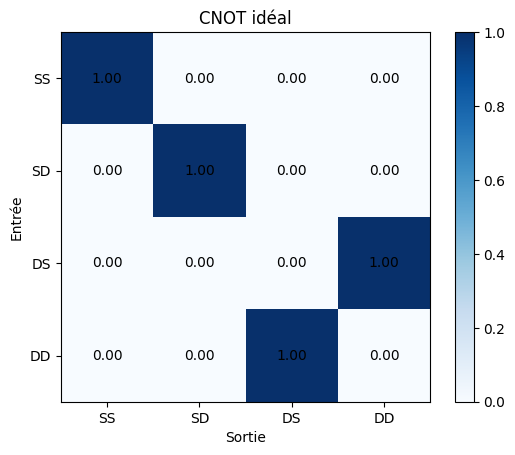

In [ ]:
import matplotlib.pyplot as plt
labels = ["SS","SD","DS","DD"]
T = truth_table(shots=1)
print(np.round(T,3))
plt.imshow(T, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(4), labels); plt.yticks(range(4), labels)
plt.xlabel("Sortie"); plt.ylabel("Entrée")
for i in range(4):
    for j in range(4): plt.text(j,i,f"{T[i,j]:.2f}",ha="center",va="center")
plt.title("CNOT idéal"); plt.colorbar(); plt.show()

## 3. Intrication : état de Bell et parité
Entrée (|S⟩+|D⟩)/√2 ⊗ |S⟩ → sortie attendue (|SS⟩+e^{iα}|DD⟩)/√2. La parité oscille en cos(2φ) pour un état intriqué (cos φ pour un état non intriqué).

Fidélité de Bell idéale : 1.0


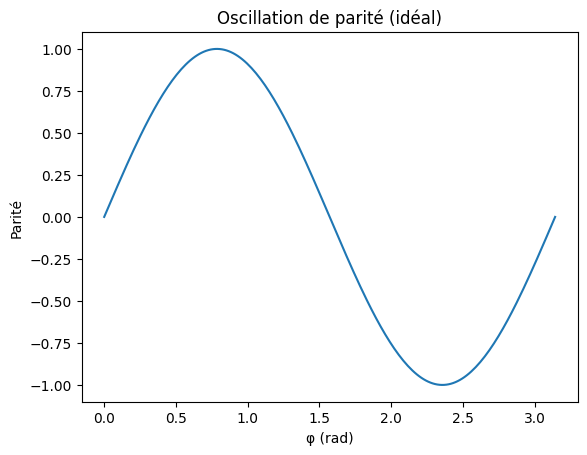

In [ ]:
rho = run(bell_input, shots=1)
print("Fidélité de Bell idéale :", round(bell_fidelity(rho),4))
phis = np.linspace(0, np.pi, 200)
plt.plot(phis, parity_curve(rho, phis))
plt.xlabel("φ (rad)"); plt.ylabel("Parité"); plt.title("Oscillation de parité (idéal)"); plt.show()

## 4. Erreurs expérimentales
Chaque source est testée seule (valeurs inspirées du Tableau 2) :
- **Excitation thermique résiduelle** du bus : 2 % de probabilité d'être dans |n=1⟩.
- **Erreur d'adressage** : 5 % de l'impulsion atteint l'ion voisin.
- **Fluctuations d'intensité** : 3 % sur l'angle de rotation.
- **Bruit de phase du laser** : écart-type σφ sur la phase de chaque impulsion (modèle simplifié de la largeur de raie).

Idéal                      table de vérité 1.000   Bell 1.000
Thermique 2 %              table de vérité 0.999   Bell 0.999
Adressage 5 %              table de vérité 0.981   Bell 0.979
Intensité 3 %              table de vérité 0.991   Bell 0.992
Bruit de phase 0.3 rad     table de vérité 0.804   Bell 0.775


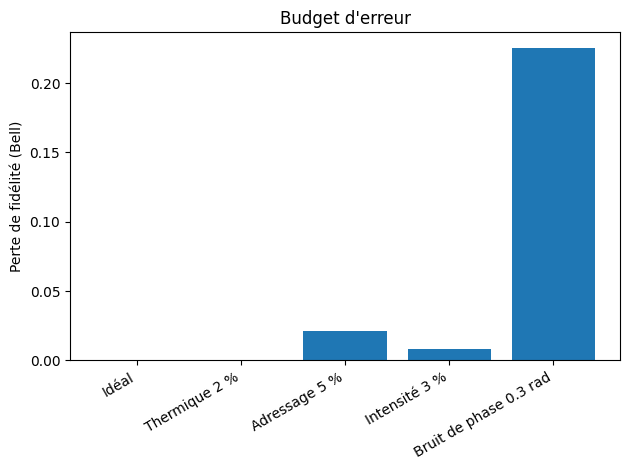

In [ ]:
cases = {
    "Idéal": dict(),
    "Thermique 2 %": dict(nth=0.02),
    "Adressage 5 %": dict(eps=0.05),
    "Intensité 3 %": dict(amp_sig=0.03),
    "Bruit de phase 0.3 rad": dict(ph_sig=0.3),
}
res = {}
for name, kw in cases.items():
    kw = dict(kw); nth = kw.pop("nth", 0.0)
    T = truth_table(shots=150, nth=nth, **kw)
    r = run(bell_input, shots=150, nth=nth, **kw)
    res[name] = (np.mean([T[0,0],T[1,1],T[2,3],T[3,2]]), bell_fidelity(r))
    print(f"{name:26s} table de vérité {res[name][0]:.3f}   Bell {res[name][1]:.3f}")
plt.bar(range(len(res)), [1-v[1] for v in res.values()])
plt.xticks(range(len(res)), res.keys(), rotation=30, ha="right")
plt.ylabel("Perte de fidélité (Bell)"); plt.title("Budget d'erreur"); plt.tight_layout(); plt.show()

## 5. Toutes les erreurs ensemble vs expérience
Le papier mesure ≈ 70–80 % sur la table de vérité et F = 0,71(3) pour l'état intriqué. Les valeurs ci-dessous dépendent du modèle simplifié de bruit de phase (σφ = 0,32 rad choisi pour s'approcher de l'expérience).

[[0.72 0.19 0.04 0.04]
 [0.19 0.73 0.04 0.05]
 [0.02 0.02 0.11 0.84]
 [0.02 0.02 0.84 0.11]]
Table de vérité (diagonale moyenne) : 0.784  (papier : 0.70-0.80)
Fidélité de Bell : 0.734  (papier : 0.71)


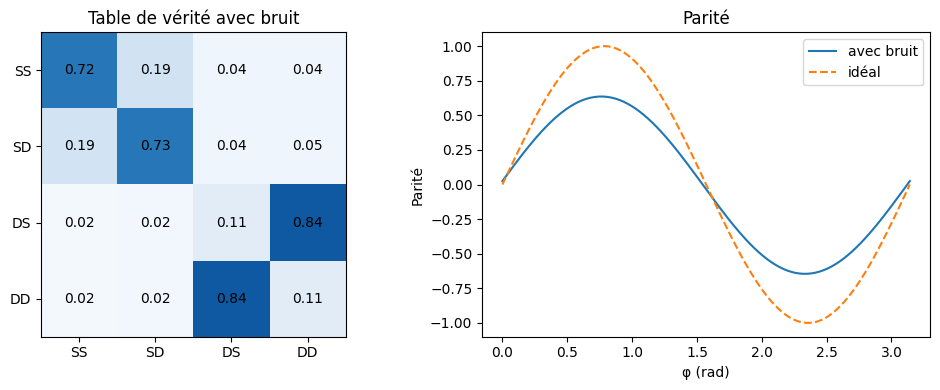

In [ ]:
kw = dict(eps=0.05, amp_sig=0.03, ph_sig=0.32)
Tn = truth_table(shots=300, nth=0.02, **kw)
rn = run(bell_input, shots=300, nth=0.02, **kw)
print(np.round(Tn,2))
print("Table de vérité (diagonale moyenne) :", round(np.mean([Tn[0,0],Tn[1,1],Tn[2,3],Tn[3,2]]),3), " (papier : 0.70-0.80)")
print("Fidélité de Bell :", round(bell_fidelity(rn),3), " (papier : 0.71)")
fig, ax = plt.subplots(1,2, figsize=(10,4))
ax[0].imshow(Tn, cmap="Blues", vmin=0, vmax=1)
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(labels); ax[0].set_yticks(range(4)); ax[0].set_yticklabels(labels)
for i in range(4):
    for j in range(4): ax[0].text(j,i,f"{Tn[i,j]:.2f}",ha="center",va="center")
ax[0].set_title("Table de vérité avec bruit")
phis = np.linspace(0, np.pi, 200)
ax[1].plot(phis, parity_curve(rn, phis), label="avec bruit")
ax[1].plot(phis, parity_curve(run(bell_input, shots=1), phis), "--", label="idéal")
ax[1].set_xlabel("φ (rad)"); ax[1].set_ylabel("Parité"); ax[1].legend(); ax[1].set_title("Parité")
plt.tight_layout(); plt.show()

## Extensions
Le module ci-dessous ajoute : le bruit de fréquence laser corrélé, la température du bus, la porte de Mølmer–Sørensen (modèle bichromatique dans la limite de Lamb–Dicke) et des utilitaires de comparaison. Le bus est maintenant tronqué à 8 niveaux de phonons.

In [ ]:
import numpy as np
from scipy.linalg import expm

# ---------- 1. bruit de phase corrélé dans le temps ----------
OMEGA_B = np.pi / 95.0      # rad/µs : pulse pi sur la bande bleue = 95 µs (papier)
OMEGA_C = 1.2566            # rad/µs : porteuse (pi/2 ~ 1.25 µs)
def duration(kind, th): return th / (OMEGA_B if kind == "b" else OMEGA_C)

def laser_phase(rng, T, sig_d, tau, dt=1.0):
    """Phase du laser phi_L(t)=int delta dt', delta = bruit de fréquence OU (écart-type sig_d rad/µs, corrélation tau µs)."""
    n = int(T / dt) + 2
    d = np.zeros(n)
    if tau <= 0:
        d = rng.normal(0, sig_d, n)
    else:
        a = np.exp(-dt / tau); s = sig_d * np.sqrt(1 - a * a)
        d[0] = rng.normal(0, sig_d)
        for i in range(1, n): d[i] = a * d[i-1] + rng.normal(0, s)
    return np.cumsum(d) * dt

def gate_corr(rng, sig_d, tau, eps=0.0):
    """Porte CZ avec bruit de fréquence laser corrélé : la phase de chaque impulsion = phi_L au milieu de l'impulsion."""
    durs = [duration(k, th) for k, j, th, ph in SEQ]
    T = sum(durs)
    phiL = laser_phase(rng, T, sig_d, tau)
    t = 0.0; U = np.eye(4 * N, dtype=complex)
    for (kind, j, th, ph), d in zip(SEQ, durs):
        dph = phiL[int(t + d / 2)]
        U = pulse(kind, j, th, ph, eps, 1.0, dph) @ U
        t += d
    return U

def thermal_n(rng, nbar):
    if nbar <= 0: return 0
    p = nbar ** np.arange(N) / (1 + nbar) ** (np.arange(N) + 1); p /= p.sum()
    return rng.choice(N, p=p)

def run_gen(psi_in_fn, gate_fn, shots=200, nbar=0.0, seed=1):
    rng = np.random.default_rng(seed)
    rho = np.zeros((4, 4), complex)
    for _ in range(shots):
        n0 = thermal_n(rng, nbar)
        out = gate_fn(rng) @ psi_in_fn(n0)
        M = out.reshape(4, N); rho += M @ M.conj().T
    return rho / shots

def diag_mean(T): return np.mean([T[0,0], T[1,1], T[2,3], T[3,2]])
def tt_gen(gate_fn, shots=200, nbar=0.0):
    T = np.zeros((4, 4))
    for i, (x, y) in enumerate([(0,0),(0,1),(1,0),(1,1)]):
        T[i] = np.real(np.diag(run_gen(lambda n0: vec(x, y, n0), gate_fn, shots, nbar)))
    return T

# ---------- 3. porte de Mølmer–Sørensen ----------
Xi = np.array([[0,1],[1,0]], complex)
def ms_ops():
    J = k3(Xi, I2, IN) + k3(I2, Xi, IN)
    A = k3(I2, I2, a); Ad = k3(I2, I2, ad)
    return J, A, Ad
def ms_gate(g, delta=2*np.pi/300.0, steps=300):
    """Evolution H(t)=g*Jx*(a e^{-i delta t}+h.c.) sur T=2pi/delta (limite Lamb-Dicke, bichromatique)."""
    J, A, Ad = ms_ops(); T = 2*np.pi/delta; dt = T/steps
    U = np.eye(4*N, dtype=complex)
    for k in range(steps):
        t = (k + 0.5) * dt
        H = g * J @ (A*np.exp(1j*delta*t) + Ad*np.exp(-1j*delta*t))
        U = expm(-1j * H * dt) @ U
    return U
def ms_ideal():
    XX = np.kron(Xi, Xi)
    return expm(-1j * np.pi/4 * XX)

# ---------- comparaisons déterministes (thermique, erreur d'amplitude) ----------
def gate_amp(e):
    U = np.eye(4 * N, dtype=complex)
    for kind, j, th, ph in SEQ: U = pulse(kind, j, th, ph, 0.0, 1 + e, 0.0) @ U
    return U
def bell_rho(U, n0=0):
    out = U @ bell_input(n0); M = out.reshape(4, N); return M @ M.conj().T
def ms_bell_rho(U, n0=0):
    out = U @ vec(0, 0, n0); M = out.reshape(4, N); return M @ M.conj().T
def thermal_weights(nbar):
    p = nbar ** np.arange(N) / (1 + nbar) ** (np.arange(N) + 1) if nbar > 0 else np.eye(N)[0]
    return p / p.sum()
def eff_unitary(U): return U.reshape(2, 2, N, 2, 2, N)[:, :, 0, :, :, 0].reshape(4, 4)

GATE_T = sum(duration(k, th) for k, j, th, ph in SEQ)
def sigma_for_phase(Phi, tau, T=GATE_T):
    """sigma_delta tel que la phase accumulée sur T ait un écart-type Phi (OU, corrélation tau)."""
    if tau <= 0: return Phi / np.sqrt(T)      # bruit blanc (dt=1 µs)
    var = 2 * tau**2 * (T / tau - 1 + np.exp(-T / tau))
    return Phi / np.sqrt(var)

## 7. Bruit de phase corrélé dans le temps
Le bruit de fréquence du laser est modélisé par un processus d'Ornstein–Uhlenbeck (écart-type σδ, temps de corrélation τ). La phase de chaque impulsion est la phase accumulée du laser au milieu de l'impulsion. La durée totale de la porte est ≈ 520 µs (le papier donne ≈ 600 µs).

Pour isoler l'effet de la corrélation, on **fixe l'écart-type de la phase accumulée sur toute la porte (Φ)** et on fait varier τ : bruit rapide (τ petit) contre dérive lente (τ grand).

Φ=0.5: [np.float64(0.882), np.float64(0.892), np.float64(0.897), np.float64(0.929), np.float64(0.941)]
Φ=1.0: [np.float64(0.659), np.float64(0.677), np.float64(0.705), np.float64(0.775), np.float64(0.799)]


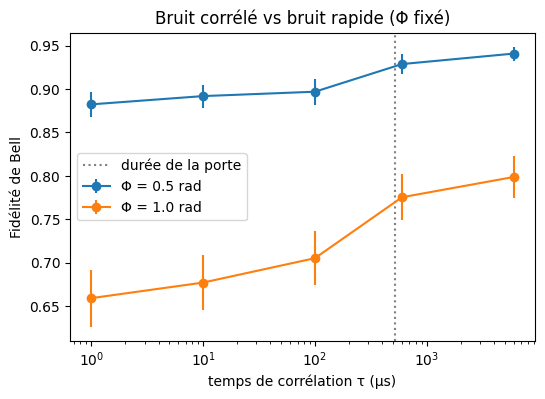

In [ ]:
taus = [1, 10, 100, 600, 6000]
fig, ax = plt.subplots(figsize=(6,4))
for Phi in [0.5, 1.0]:
    m, e = [], []
    for tau in taus:
        sd = sigma_for_phase(Phi, tau)
        F = [bell_fidelity(bell_rho(gate_corr(np.random.default_rng(s), sd, tau))) for s in range(80)]
        m.append(np.mean(F)); e.append(np.std(F)/np.sqrt(len(F)))
    ax.errorbar(taus, m, yerr=e, marker="o", label=f"Φ = {Phi} rad")
    print(f"Φ={Phi}:", [round(x,3) for x in m])
ax.axvline(GATE_T, color="gray", ls=":", label="durée de la porte")
ax.set_xscale("log"); ax.set_xlabel("temps de corrélation τ (µs)"); ax.set_ylabel("Fidélité de Bell")
ax.legend(); ax.set_title("Bruit corrélé vs bruit rapide (Φ fixé)"); plt.show()

**Lecture** : à même phase accumulée, un bruit lent (dérive, τ ≳ durée de la porte) coûte moins qu'un bruit rapide, (une explication plausible, non vérifiée ici : la structure Ramsey de la porte compense en partie une phase quasi constante). Les dérives lentes et le bruit rapide n'ont donc pas le même poids dans le budget d'erreur.
*Limite* : le modèle ne tient compte que de la phase des impulsions, pas du désaccord pendant les impulsions.

## 8. États excités du bus
Le CNOT de Cirac–Zoller suppose le bus dans |n=0⟩ : la fréquence de Rabi de la bande bleue vaut Ω√(n+1), donc un phonon de trop désaccorde les rotations. On teste (a) des états de Fock |n⟩ purs, (b) un état thermique de moyenne n̄.

Fidélité de Bell pour un bus dans |n> :
  n = 0 : 1.0
  n = 1 : 0.952
  n = 2 : 0.331
  n = 3 : 0.321


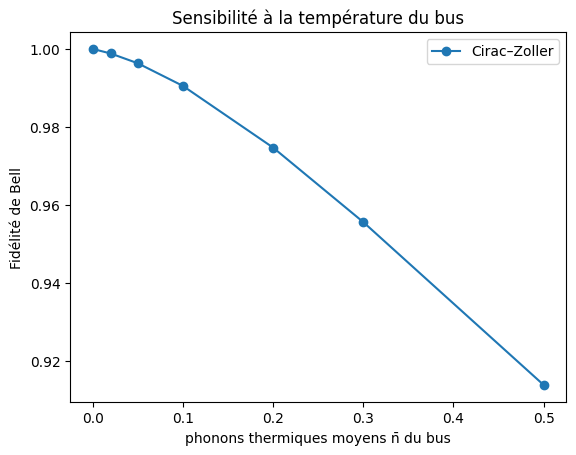

In [ ]:
Ucz = gate_amp(0.0)
print("Fidélité de Bell pour un bus dans |n> :")
for n0 in range(4):
    print(f"  n = {n0} :", round(bell_fidelity(bell_rho(Ucz, n0)), 3))

nbars = [0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]
Fth = []
for nb in nbars:
    w = thermal_weights(nb)
    Fth.append(sum(w[n] * bell_fidelity(bell_rho(Ucz, n)) for n in range(6)))
plt.plot(nbars, Fth, "o-", label="Cirac–Zoller")
plt.xlabel("phonons thermiques moyens n̄ du bus"); plt.ylabel("Fidélité de Bell"); plt.legend()
plt.title("Sensibilité à la température du bus"); plt.show()

La fidélité chute vite dès que n̄ dépasse quelques %. D'où le refroidissement par bande latérale (≈ 99 % dans |n=0⟩ dans le papier) : le résidu thermique est une des sources du Tableau 2. *Remarque* : la moyenne thermique est pondérée sur n = 0…5 ; l'état |n=1⟩ est le principal contributeur.

## 9. Comparaison avec la porte de Mølmer–Sørensen
Dans la porte MS, deux tons bichromatiques désaccordés de ±δ de la bande latérale couplent les deux ions : H(t) = g (σx¹+σx²)(a e^{iδt} + a† e^{-iδt}). Après T = 2π/δ le bus revient à son état initial et les ions ont acquis la phase de exp(−iπ/4 σx⊗σx) pour g = δ/4. **On travaille ici dans la limite de Lamb–Dicke au premier ordre**, où la porte est (presque) indépendante de n̄. Les effets d'ordre supérieur (qui limitent la MS réelle) ne sont pas modélisés.

Fidélité de la porte MS idéale : 1.0
Bell depuis |SS> : 1.0


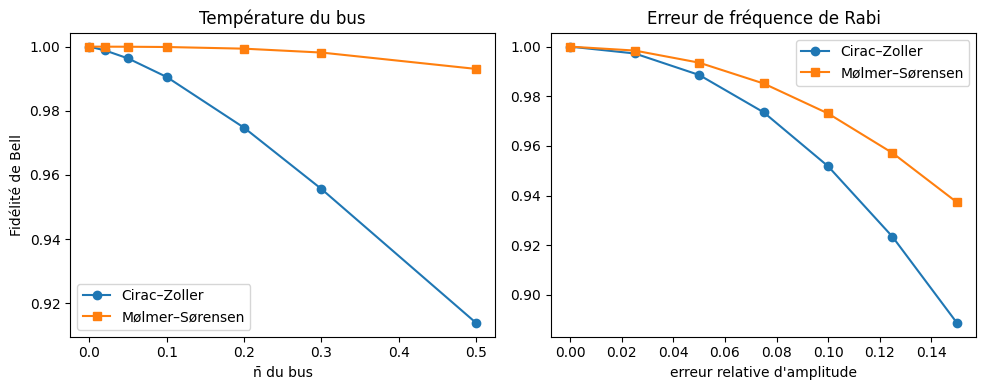

In [ ]:
delta = 2*np.pi/300.0
g0 = delta/4
Ums = ms_gate(g0)
Ue_ms = eff_unitary(Ums)
Xi2 = np.kron(Xi, Xi)
print("Fidélité de la porte MS idéale :", round(abs(np.trace(ms_ideal().conj().T @ Ue_ms))**2/16, 4))
print("Bell depuis |SS> :", round(bell_fidelity(ms_bell_rho(Ums)), 4))

# sensibilité thermique : CZ vs MS
Fms = []
for nb in nbars:
    w = thermal_weights(nb)
    Fms.append(sum(w[n] * bell_fidelity(ms_bell_rho(Ums, n)) for n in range(6)))
# erreur d'amplitude (Rabi)
eps = np.linspace(0, 0.15, 7)
Fcz_a = [bell_fidelity(bell_rho(gate_amp(e))) for e in eps]
Fms_a = [bell_fidelity(ms_bell_rho(ms_gate(g0*(1+e)))) for e in eps]

fig, ax = plt.subplots(1, 2, figsize=(10,4))
ax[0].plot(nbars, Fth, "o-", label="Cirac–Zoller"); ax[0].plot(nbars, Fms, "s-", label="Mølmer–Sørensen")
ax[0].set_xlabel("n̄ du bus"); ax[0].set_ylabel("Fidélité de Bell"); ax[0].legend(); ax[0].set_title("Température du bus")
ax[1].plot(eps, Fcz_a, "o-", label="Cirac–Zoller"); ax[1].plot(eps, Fms_a, "s-", label="Mølmer–Sørensen")
ax[1].set_xlabel("erreur relative d'amplitude"); ax[1].legend(); ax[1].set_title("Erreur de fréquence de Rabi")
plt.tight_layout(); plt.show()

**Lecture** : dans ce modèle la MS est nettement moins sensible à l'état du bus, ce qui explique son usage dominant dans les expériences récentes. Attention : la faible baisse résiduelle de la MS vient en grande partie de la troncature de l'espace de phonons, pas de la physique. Les deux portes réagissent de façon comparable à une erreur d'amplitude.

## 10. Export vers Qiskit
On place la porte simulée dans un circuit Qiskit (ordre des qubits : ion 1 = q1, ion 2 = q0).

**Résultat important** : l'opérateur effectif de la séquence du Tableau 1 (bloc |n=0⟩ du bus) est −CY, c'est-à-dire un CNOT **à des rotations locales près** (CY = S·CX·S† sur la cible). Les populations de la table de vérité sont celles d'un CNOT, mais les phases diffèrent, ce que le papier ne montre pas (il ne présente que des probabilités).

In [ ]:
!pip install -q qiskit qiskit-aer

In [ ]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator, process_fidelity
from qiskit.circuit.library import RXXGate
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

# 1) CZ simulée -> circuit Qiskit
cz_circ = QuantumCircuit(2, name="CZ_gate")
cz_circ.sdg(0); cz_circ.cx(1, 0); cz_circ.s(0)          # = CY (ion1 contrôle, ion2 cible), global -1
Ue = eff_unitary(gate_amp(0.0))
print("Fidélité de processus  simulation CZ  vs  circuit exporté :", round(process_fidelity(Operator(Ue), Operator(cz_circ)), 6))
ref = QuantumCircuit(2); ref.cx(1, 0)
print("Fidélité de processus  simulation CZ  vs  CNOT pur        :", round(process_fidelity(Operator(Ue), Operator(ref)), 3))

# 2) MS simulée -> RXX(pi/2), puis CNOT à partir de la MS (décomposition de Maslov)
ms_circ = QuantumCircuit(2); ms_circ.append(RXXGate(np.pi/2), [0, 1])
print("MS simulée vs RXX(π/2) :", round(process_fidelity(Operator(Ue_ms), Operator(ms_circ)), 6))
cnot_ms = QuantumCircuit(2)
cnot_ms.ry(np.pi/2, 1); cnot_ms.append(RXXGate(np.pi/2), [1, 0]); cnot_ms.rx(-np.pi/2, 1); cnot_ms.rx(-np.pi/2, 0); cnot_ms.ry(-np.pi/2, 1)
print("CNOT construit avec la MS vs CX :", round(process_fidelity(Operator(cnot_ms), Operator(ref)), 6))
print(cnot_ms.draw())

Input channel is not TP. Tr_2[Choi] - I has non-zero eigenvalues: [-5.19734613e-06 -5.19734613e-06]


Fidélité de processus  simulation CZ  vs  circuit exporté : 1.0
Fidélité de processus  simulation CZ  vs  CNOT pur        : 0.25
MS simulée vs RXX(π/2) : 0.999997
CNOT construit avec la MS vs CX : 1.0
                ┌───────────┐┌──────────┐            
q_0: ───────────┤1          ├┤ Rx(-π/2) ├────────────
     ┌─────────┐│  Rxx(π/2) │├──────────┤┌──────────┐
q_1: ┤ Ry(π/2) ├┤0          ├┤ Rx(-π/2) ├┤ Ry(-π/2) ├
     └─────────┘└───────────┘└──────────┘└──────────┘


Qiskit + dépolarisant (λ = 0.355) : {'00': 0.405, '01': 0.092, '10': 0.095, '11': 0.409}
Papier : P(SS)=0.42, P(DD)=0.45 avant analyse (F = 0.71)


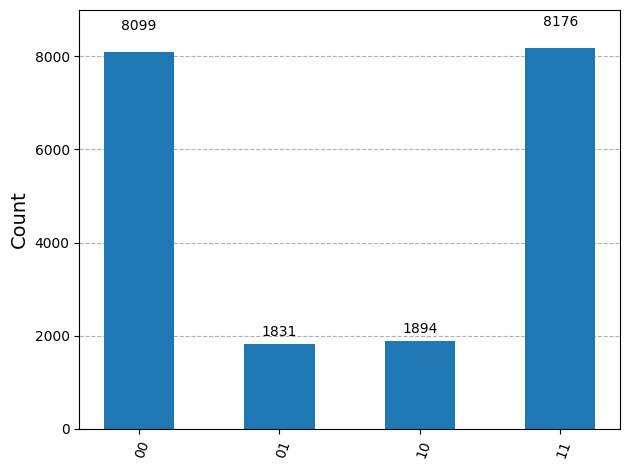

In [ ]:
# 3) Bruit : un modèle dépolarisant ajusté sur la fidélité de Bell simulée (avec bruit), comparé au papier
F_target = bell_fidelity(rn)                      # fidélité de Bell avec toutes les erreurs (partie 5)
lam = (1 - F_target) * 4/3                        # rho -> (1-lam) rho + lam I/4  =>  F = 1 - 3 lam/4
noise = NoiseModel(); noise.add_all_qubit_quantum_error(depolarizing_error(lam, 2), ["cx"])
sim = AerSimulator(noise_model=noise)
bell = QuantumCircuit(2, 2); bell.h(1); bell.cx(1, 0); bell.measure([1, 0], [0, 1])
counts = sim.run(transpile(bell, sim), shots=20000, seed_simulator=1).result().get_counts()
tot = sum(counts.values())
print("Qiskit + dépolarisant (λ = %.3f) :" % lam, {k: round(v/tot, 3) for k, v in sorted(counts.items())})
print("Papier : P(SS)=0.42, P(DD)=0.45 avant analyse (F = 0.71)")
from qiskit.visualization import plot_histogram
plot_histogram(counts)

## 11. Conclusion
- La séquence du Tableau 1 donne un CNOT en populations, et −CY (CNOT à rotations locales près) en opérateur complet.
- Le bruit de phase du laser domine le budget d'erreur ; à phase accumulée égale, les dérives lentes sont moins néfastes que le bruit rapide.
- La porte de Cirac–Zoller est très sensible à l'état du bus (il faut n ≈ 0), la Mølmer–Sørensen non (dans la limite de Lamb–Dicke au premier ordre).
- Le modèle dépolarisant Qiskit reproduit la fidélité mais pas la structure des erreurs (la simulation physique en garde la trace : erreurs asymétriques, fuite hors du sous-espace).

**Limites** : bruit de phase phénoménologique, MS au premier ordre de Lamb–Dicke, pas de décohérence spontanée ni de désaccord pendant les impulsions.